In [1]:
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.losses import mean_squared_error, mean_absolute_error

import os
import time
import matplotlib.pyplot as plt
import numpy as np
import tensorflow_datasets as tfds

In [2]:
def normalize(input_image, label):  
    input_image = tf.cast(input_image, tf.float32)
    input_image = (input_image / 127.5) - 1
    return input_image

# Though we need only label we are passing two lasbels else will get: TypeError: tf__normalize() takes 1 positional argument but 2 were given



In [3]:
dataset, metadata = tfds.load('cycle_gan/summer2winter_yosemite', with_info=True, as_supervised=True)

In [4]:
train_A, train_B = dataset['trainA'], dataset['trainB'] 
test_A, test_B = dataset['testA'], dataset['testB'] 

In [5]:
BUFFER_SIZE = 1000
BATCH_SIZE = 1
IMG_WIDTH = 256
IMG_HEIGHT = 256
EPOCHS = 50
AUTOTUNE = tf.data.experimental.AUTOTUNE

In [6]:
train_A = train_A.map(normalize, num_parallel_calls=AUTOTUNE).cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
train_B = train_B.map(normalize, num_parallel_calls=AUTOTUNE).cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
test_A = test_A.map(normalize, num_parallel_calls=AUTOTUNE).cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
test_B = test_B.map(normalize, num_parallel_calls=AUTOTUNE).cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
    


In [7]:
inpA = next(iter(train_A))
inpB = next(iter(train_B))

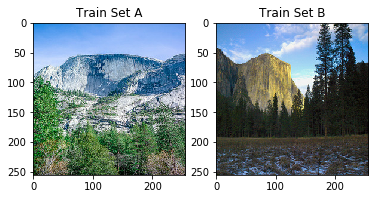

In [8]:
plt.subplot(121)
plt.title("Train Set A")
plt.imshow(inpA[0]*0.5 + 0.5)
plt.subplot(122)
plt.title("Train Set B")
plt.imshow(inpB[0]*0.5 + 0.5)

In [9]:
def downsample(filters, size=3, apply_batchnorm=True):
    initializer = tf.random_normal_initializer(0., 0.02)

    result = tf.keras.Sequential()
    result.add(
      tf.keras.layers.Conv2D(filters, size, strides=2, padding='same',
                             kernel_initializer=initializer, use_bias=False))
    if apply_batchnorm:
        result.add(tf.keras.layers.BatchNormalization())
    result.add(tf.keras.layers.LeakyReLU())

    return result

In [10]:
def upsample(filters, size=3, apply_dropout=False):
    initializer = tf.random_normal_initializer(0., 0.02)

    result = tf.keras.Sequential()
    result.add(
    tf.keras.layers.Conv2DTranspose(filters, size, strides=2,
                                    padding='same',
                                    kernel_initializer=initializer,
                                    use_bias=False))

    result.add(tf.keras.layers.BatchNormalization())

    if apply_dropout:
        result.add(tf.keras.layers.Dropout(0.5))

    result.add(tf.keras.layers.ReLU())

    return result

In [11]:
class ResnetIdentityBlock(tf.keras.Model):
  def __init__(self, kernel_size, filters):
    super(ResnetIdentityBlock, self).__init__(name='')
    filters1, filters2, filters3 = filters

    self.conv2a = tf.keras.layers.Conv2D(filters1, (1, 1))
    self.bn2a = tf.keras.layers.BatchNormalization()

    self.conv2b = tf.keras.layers.Conv2D(filters2, kernel_size, padding='same')
    self.bn2b = tf.keras.layers.BatchNormalization()

    self.conv2c = tf.keras.layers.Conv2D(filters3, (1, 1))
    self.bn2c = tf.keras.layers.BatchNormalization()

  def call(self, input_tensor, training=False):
    x = self.conv2a(input_tensor)
    x = self.bn2a(x, training=training)
    x = tf.nn.relu(x)

    x = self.conv2b(x)
    x = self.bn2b(x, training=training)
    x = tf.nn.relu(x)

    x = self.conv2c(x)
    x = self.bn2c(x, training=training)

    x += input_tensor
    return tf.nn.relu(x)

    
block1 = ResnetIdentityBlock(3, [512, 512, 512])
block2 = ResnetIdentityBlock(3, [512, 512, 512])
block3 = ResnetIdentityBlock(3, [512, 512, 512])


resnet = [block1, block2, block3]
print(block1(tf.zeros([1, 16, 16, 512])).shape)
print([x.name for x in block1.trainable_variables])

(1, 16, 16, 512)
['resnet_identity_block/conv2d/kernel:0', 'resnet_identity_block/conv2d/bias:0', 'resnet_identity_block/batch_normalization/gamma:0', 'resnet_identity_block/batch_normalization/beta:0', 'resnet_identity_block/conv2d_1/kernel:0', 'resnet_identity_block/conv2d_1/bias:0', 'resnet_identity_block/batch_normalization_1/gamma:0', 'resnet_identity_block/batch_normalization_1/beta:0', 'resnet_identity_block/conv2d_2/kernel:0', 'resnet_identity_block/conv2d_2/bias:0', 'resnet_identity_block/batch_normalization_2/gamma:0', 'resnet_identity_block/batch_normalization_2/beta:0']


In [12]:
def Generator():
    down_stack = [
        downsample(64, 4, apply_batchnorm=False), 
        downsample(128, 4),
        downsample(256, 4), 
        downsample(512, 4) 
    ]

    up_stack = [
        upsample(256, 4),
        upsample(128, 4), 
        upsample(64, 4), 
    ]

    initializer = tf.random_normal_initializer(0., 0.02)
    last = tf.keras.layers.Conv2DTranspose(3, 4,
                                         strides=2,
                                         padding='same',
                                         kernel_initializer=initializer,
                                         activation='tanh') 


    inputs = tf.keras.layers.Input(shape=[256, 256, 3])
    x = inputs

    # Downsampling through the model
    skips = []
    for down in down_stack:
        x = down(x)
        skips.append(x)
        
    for block in resnet:
        x = block(x)

    skips = reversed(skips[:-1])

    # Upsampling and establishing the skip connections
    for up, skip in zip(up_stack, skips):
        concat = tf.keras.layers.Concatenate()
        x = up(x)
        x = concat([x, skip])

    x = last(x)

    return tf.keras.Model(inputs=inputs, outputs=x)

In [13]:
generator = Generator()

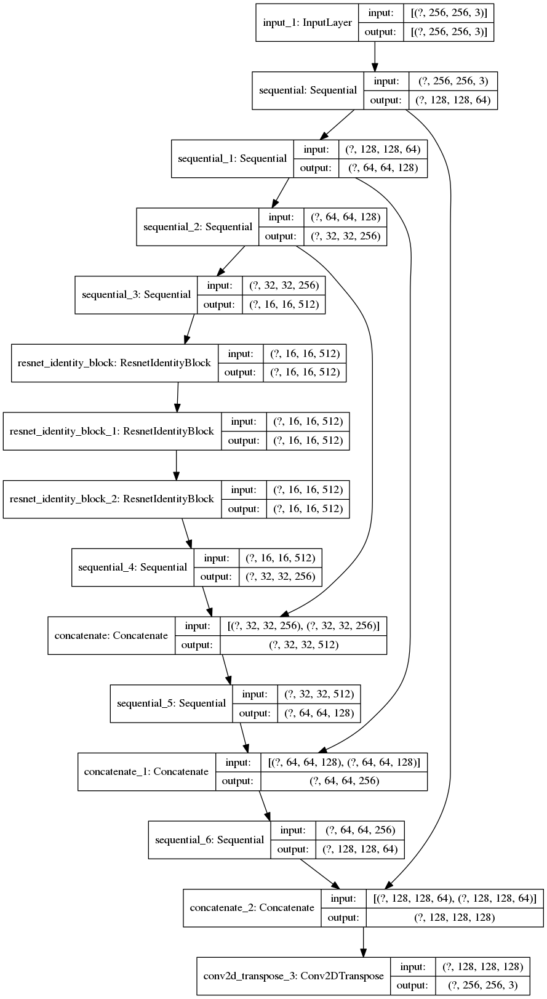

In [14]:
tf.keras.utils.plot_model(generator, 'generator.png', show_shapes=True)

In [15]:
generator.summary()

Model: "model"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_1 (InputLayer)            [(None, 256, 256, 3) 0                                            
__________________________________________________________________________________________________
sequential (Sequential)         (None, 128, 128, 64) 3072        input_1[0][0]                    
__________________________________________________________________________________________________
sequential_1 (Sequential)       (None, 64, 64, 128)  131584      sequential[0][0]                 
__________________________________________________________________________________________________
sequential_2 (Sequential)       (None, 32, 32, 256)  525312      sequential_1[0][0]               
______________________________________________________________________________________________

(1, 256, 256, 3) 0.5381467 0.4571539


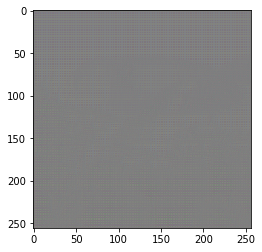

In [16]:
gen_output = generator(inpA, training=False)
gen_output = (gen_output + 1) / 2
plt.imshow(gen_output[0])
print(gen_output.shape,gen_output[0,...].numpy().max(), gen_output[0,...].numpy().min())

In [17]:
def Discriminator():
    inputs = tf.keras.layers.Input(shape=[None,None,3])
    x = inputs
    g_filter = 64
    
    down_stack = [
        downsample(g_filter),
        downsample(g_filter * 2),
        downsample(g_filter * 4),
        downsample(g_filter * 8),
    ]
    
    for down in down_stack:
        x = down(x)

    last = tf.keras.layers.Conv2D(1, 4, strides=1, padding='same') # (bs, 30, 30, 1)
    x = last(x)

    return tf.keras.Model(inputs=inputs, outputs=x)

In [18]:
discriminator = Discriminator()
dis_output = discriminator(inpA, training=False)
print(dis_output.shape)

(1, 16, 16, 1)


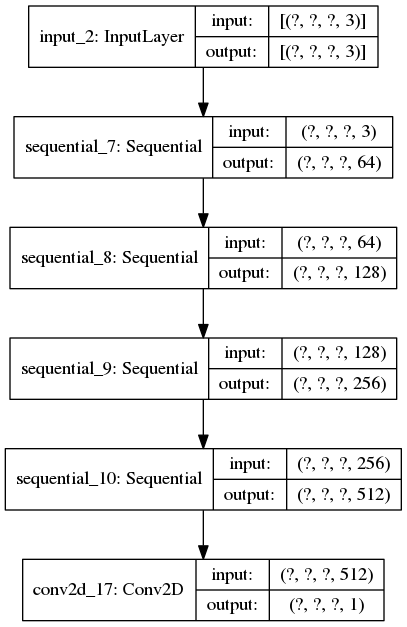

In [19]:
tf.keras.utils.plot_model(discriminator, 'discriminator.png', show_shapes=True)

In [20]:
discriminator_A = Discriminator()
discriminator_B = Discriminator()

generator_AB = Generator()
generator_BA = Generator()

In [21]:
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=True)

In [22]:
@tf.function
def discriminator_loss(disc_real_output, disc_generated_output):
    real_loss = loss_object(tf.ones_like(disc_real_output), disc_real_output)
    generated_loss = loss_object(tf.zeros_like(disc_generated_output), disc_generated_output)
    total_disc_loss = real_loss + generated_loss
    return total_disc_loss

In [23]:
optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)

In [24]:
valid = np.ones((BATCH_SIZE, 16, 16, 1)).astype('float32')
fake = np.zeros((BATCH_SIZE, 16, 16, 1)).astype('float32')

In [25]:
@tf.function
def train_batch(imgs_A, imgs_B):
    with tf.GradientTape() as g, tf.GradientTape() as d_tape:
        fake_B = generator_AB(imgs_A, training=True)
        fake_A = generator_BA(imgs_B, training=True)
        
        logits_real_A = discriminator_A(imgs_A, training=True)
        logits_fake_A = discriminator_A(fake_A, training=True)
        dA_loss = discriminator_loss(logits_real_A, logits_fake_A)
        
        logits_real_B = discriminator_B(imgs_B, training=True)
        logits_fake_B = discriminator_B(fake_B, training=True)
        dB_loss = discriminator_loss(logits_real_B, logits_fake_B)
        
        d_loss = (dA_loss + dB_loss) / 2
        # Translate images back to original domain
        reconstr_A = generator_BA(fake_B, training=True)
        reconstr_B = generator_AB(fake_A, training=True)
        
        id_A = generator_BA(imgs_A, training=True)
        id_B = generator_AB(imgs_B, training=True)


        gen_loss = tf.math.reduce_sum([
            1 * tf.math.reduce_mean(mean_squared_error(logits_fake_A, valid)),
            1 * tf.math.reduce_mean(mean_squared_error(logits_fake_B, valid)),
            10 * tf.math.reduce_mean(mean_squared_error(reconstr_A, imgs_A)),
            10 * tf.math.reduce_mean(mean_squared_error(reconstr_B, imgs_B)),
            0.1 * tf.math.reduce_mean(mean_squared_error(id_A, imgs_A)),
            0.1 * tf.math.reduce_mean(mean_squared_error(id_B, imgs_B)),
        ])
        
    gradients_of_d = d_tape.gradient(d_loss, discriminator_A.trainable_variables + discriminator_B.trainable_variables)
    discriminator_optimizer.apply_gradients(zip(gradients_of_d, discriminator_A.trainable_variables + discriminator_B.trainable_variables))

    gradients_of_generator = g.gradient(gen_loss, generator_AB.trainable_variables + generator_BA.trainable_variables)
    optimizer.apply_gradients(zip(gradients_of_generator, generator_AB.trainable_variables + generator_BA.trainable_variables))
    
    return dA_loss, dB_loss, gen_loss

In [26]:
checkpoint_dird_A = './training_checkpointsd_A'
checkpoint_prefixd_A = os.path.join(checkpoint_dird_A, "ckpt_{epoch}")

checkpoint_dird_B = './training_checkpointsd_B'
checkpoint_prefixd_B = os.path.join(checkpoint_dird_B, "ckpt_{epoch}")

checkpoint_dirg_AB = './training_checkpointsg_AB'
checkpoint_prefixg_AB = os.path.join(checkpoint_dirg_AB, "ckpt_{epoch}")

checkpoint_dirg_BA = './training_checkpointsg_BA'
checkpoint_prefixg_BA = os.path.join(checkpoint_dirg_BA, "ckpt_{epoch}")

In [27]:
def train(trainA_, trainB_, epochs):
    for epoch in range(epochs):
        start = time.time()
        
        for batch_i, (imgs_A, imgs_B) in enumerate(zip(trainA_, trainB_)):
            dA_loss, dB_loss, g_loss = train_batch(imgs_A, imgs_B)
            
            if batch_i % 1000 == 0:
                test_imgA = next(iter(test_A))
                test_imgB = next(iter(test_B))
                print ('Time taken for epoch {} batch index {} is {} seconds\n'.format(epoch, batch_i, time.time()-start))
                print("discriminator A: ", dA_loss.numpy())
                print("discriminator B: ", dB_loss.numpy())
                print("generator: {}\n".format(g_loss))

                fig, axs = plt.subplots(2, 2, figsize=(10, 10), sharey=True, sharex=True)
                gen_outputA = generator_AB(test_imgA, training=False)
                gen_outputB = generator_BA(test_imgB, training=False)
                axs[0,0].imshow(test_imgA[0]*0.5 + 0.5)
                axs[0,0].set_title("Generator A Input")
                axs[0,1].imshow(gen_outputA[0]*0.5 + 0.5)
                axs[0,1].set_title("Generator A Output")
                axs[1,0].imshow(test_imgB[0]*0.5 + 0.5)
                axs[1,0].set_title("Generator B Input")
                axs[1,1].imshow(gen_outputB[0]*0.5 + 0.5)
                axs[1,1].set_title("Generator B Output")
                plt.show()

                discriminator_A.save_weights(checkpoint_prefixd_A.format(epoch=epoch))
                discriminator_B.save_weights(checkpoint_prefixd_B.format(epoch=epoch))
                generator_AB.save_weights(checkpoint_prefixg_AB.format(epoch=epoch))
                generator_BA.save_weights(checkpoint_prefixg_BA.format(epoch=epoch))

Instructions for updating:
Use tf.where in 2.0, which has the same broadcast rule as np.where


Instructions for updating:
Use tf.where in 2.0, which has the same broadcast rule as np.where


Time taken for epoch 0 batch index 0 is 13.181012153625488 seconds

discriminator A:  1.6280994
discriminator B:  1.5620365
generator: 11.12416934967041



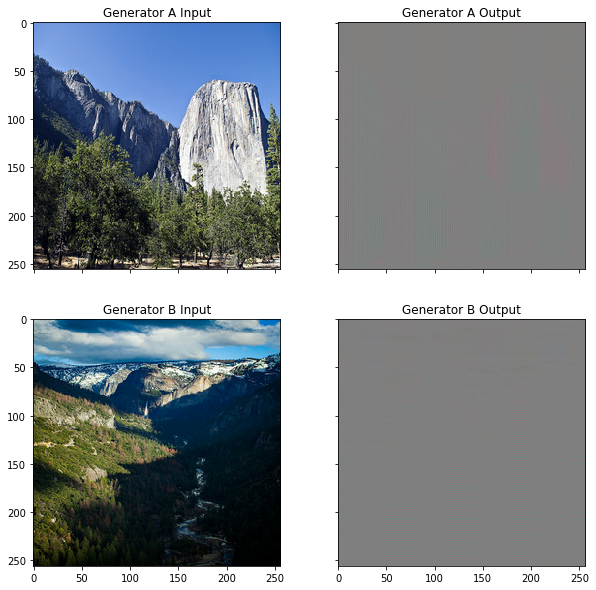

Time taken for epoch 1 batch index 0 is 0.27576684951782227 seconds

discriminator A:  1.4068083
discriminator B:  1.382077
generator: 2.7275571823120117



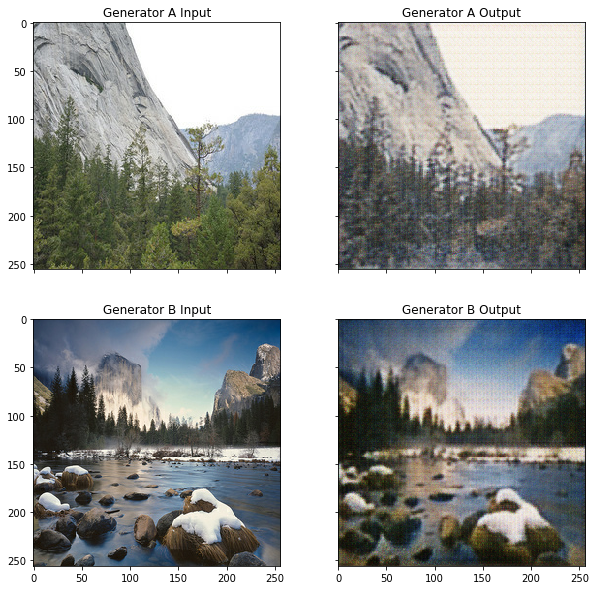

Time taken for epoch 2 batch index 0 is 0.28611111640930176 seconds

discriminator A:  1.4227195
discriminator B:  1.3502276
generator: 2.6172499656677246



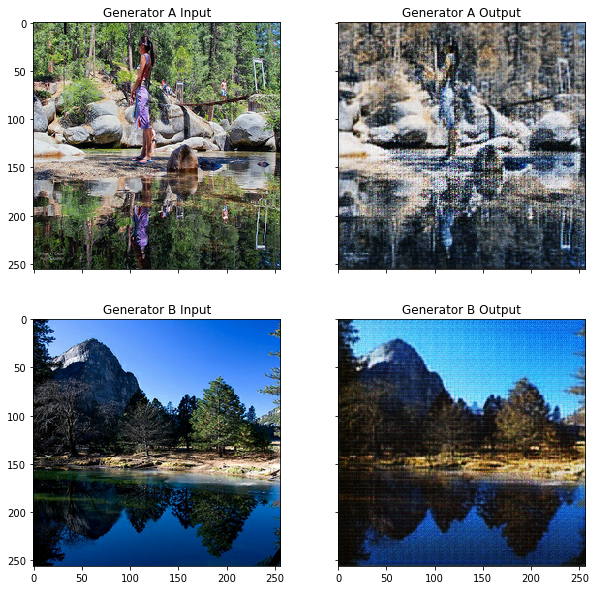

Time taken for epoch 3 batch index 0 is 0.28316211700439453 seconds

discriminator A:  1.326968
discriminator B:  1.379494
generator: 2.806941032409668



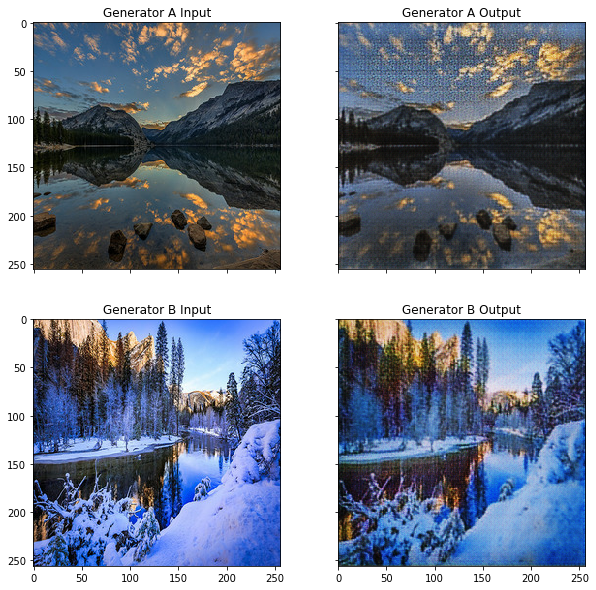

Time taken for epoch 4 batch index 0 is 0.28876447677612305 seconds

discriminator A:  1.4003315
discriminator B:  1.3918089
generator: 2.325714111328125



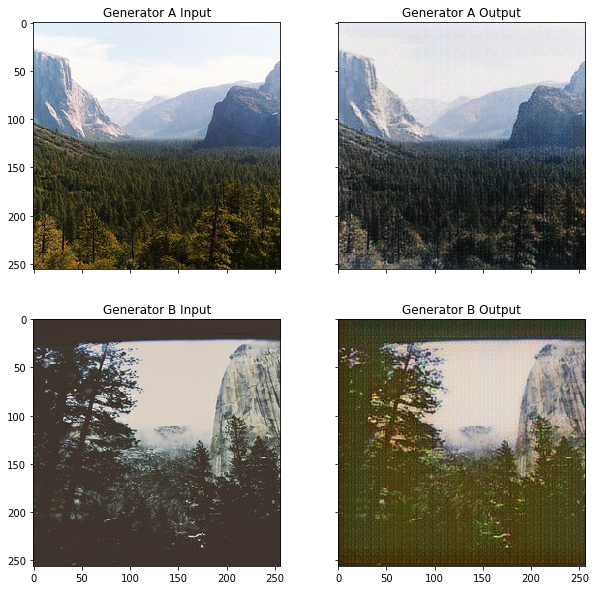

Time taken for epoch 5 batch index 0 is 0.2875247001647949 seconds

discriminator A:  1.3905141
discriminator B:  1.3873987
generator: 2.105024576187134



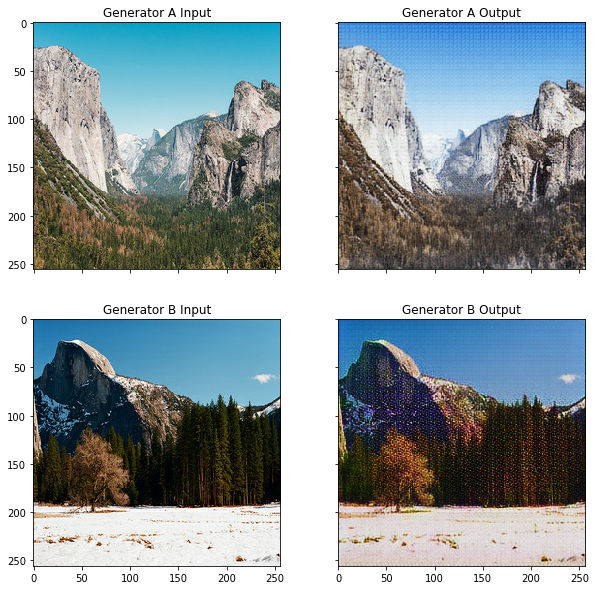

Time taken for epoch 6 batch index 0 is 0.28786706924438477 seconds

discriminator A:  1.3918222
discriminator B:  1.3966067
generator: 2.337167501449585



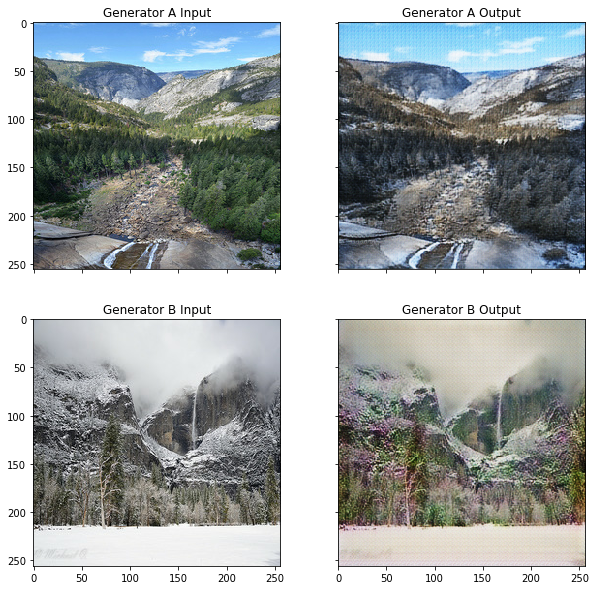

Time taken for epoch 7 batch index 0 is 0.29190921783447266 seconds

discriminator A:  1.3891311
discriminator B:  1.4038012
generator: 2.358767032623291



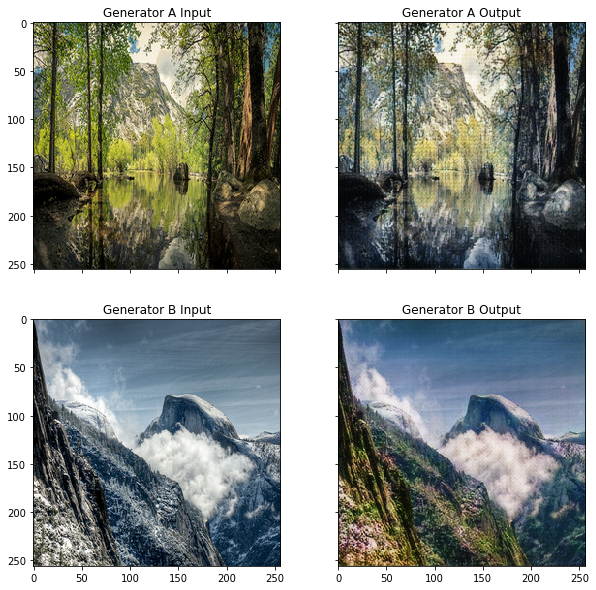

Time taken for epoch 8 batch index 0 is 0.2991328239440918 seconds

discriminator A:  1.4098598
discriminator B:  1.3959091
generator: 2.1906089782714844



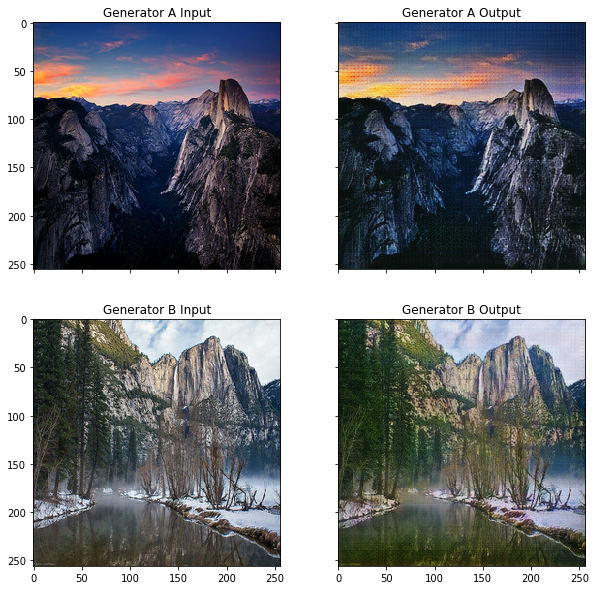

Time taken for epoch 9 batch index 0 is 0.2918128967285156 seconds

discriminator A:  1.3858881
discriminator B:  1.3817523
generator: 2.261160373687744



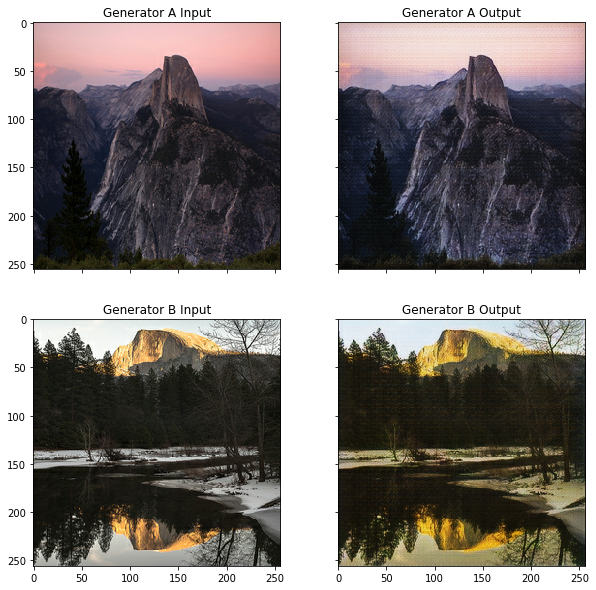

Time taken for epoch 10 batch index 0 is 0.29442739486694336 seconds

discriminator A:  1.3866847
discriminator B:  1.3826226
generator: 2.1767830848693848



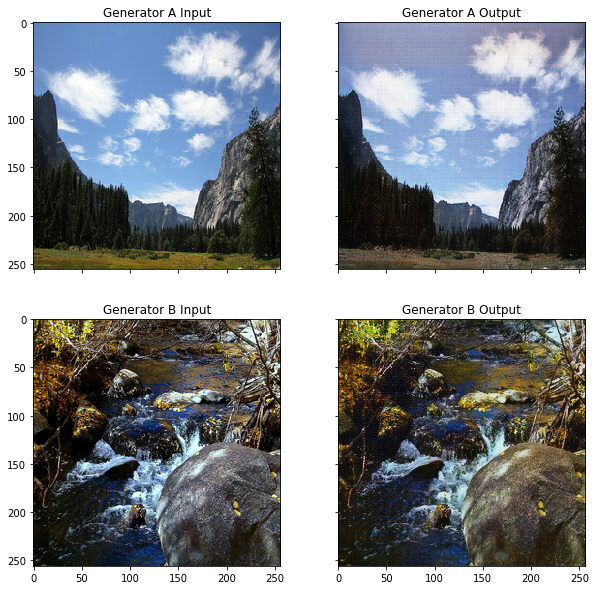

Time taken for epoch 11 batch index 0 is 0.29236435890197754 seconds

discriminator A:  1.4061885
discriminator B:  1.3839881
generator: 2.282371759414673



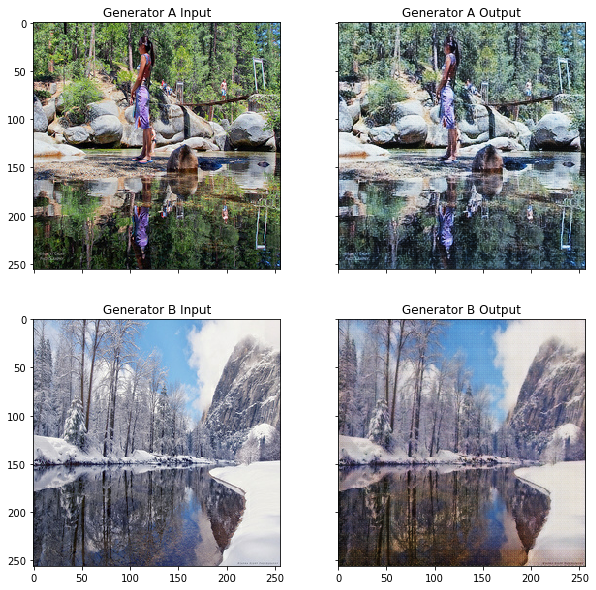

Time taken for epoch 12 batch index 0 is 0.29627203941345215 seconds

discriminator A:  1.3900853
discriminator B:  1.4184339
generator: 2.2810256481170654



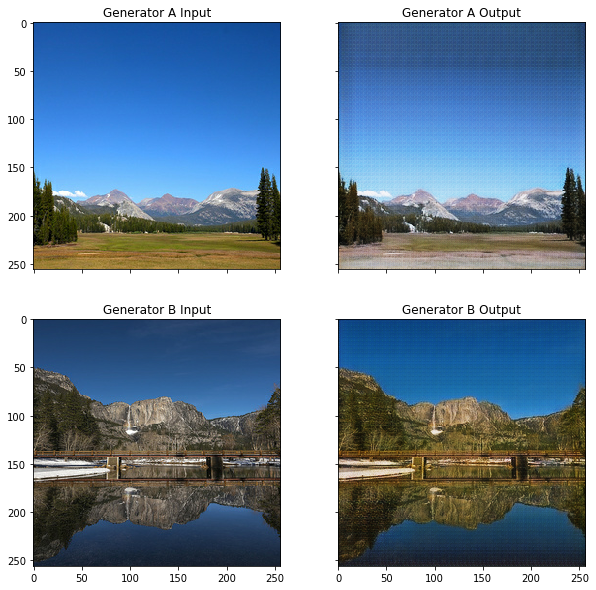

Time taken for epoch 13 batch index 0 is 0.2970149517059326 seconds

discriminator A:  1.4063714
discriminator B:  1.4074318
generator: 2.0557730197906494



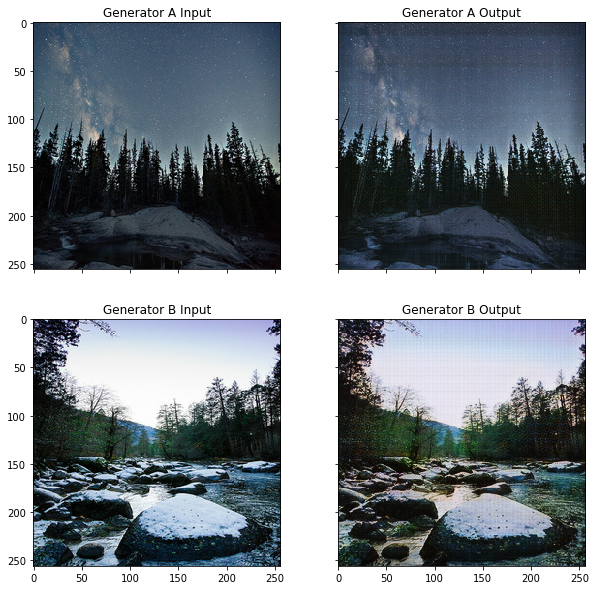

Time taken for epoch 14 batch index 0 is 0.2952568531036377 seconds

discriminator A:  1.3892033
discriminator B:  1.4026514
generator: 2.101701498031616



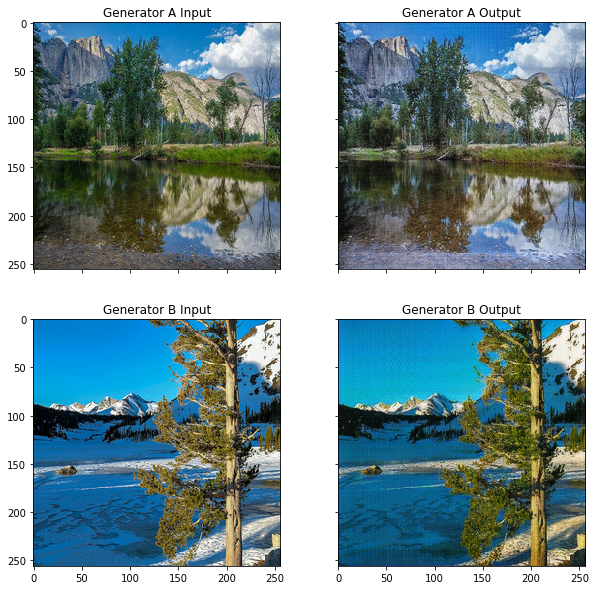

Time taken for epoch 15 batch index 0 is 0.3061807155609131 seconds

discriminator A:  1.3932836
discriminator B:  1.4016514
generator: 2.343909502029419



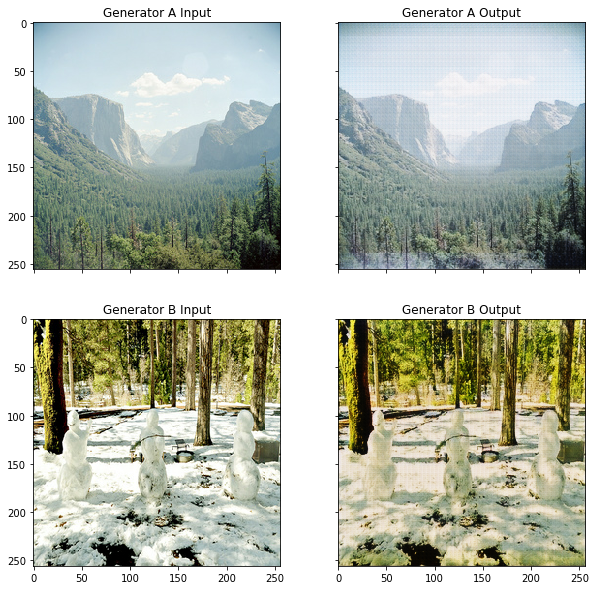

Time taken for epoch 16 batch index 0 is 0.29912495613098145 seconds

discriminator A:  1.3938315
discriminator B:  1.4059
generator: 1.9937580823898315



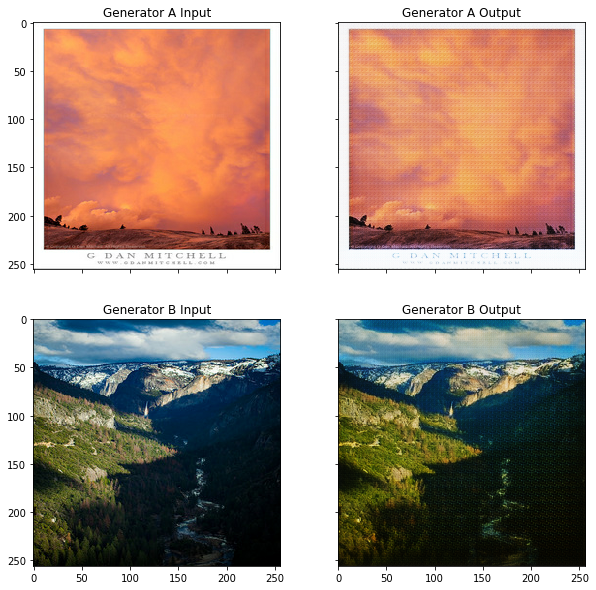

Time taken for epoch 17 batch index 0 is 0.3048384189605713 seconds

discriminator A:  1.3846998
discriminator B:  1.3865342
generator: 2.042872905731201



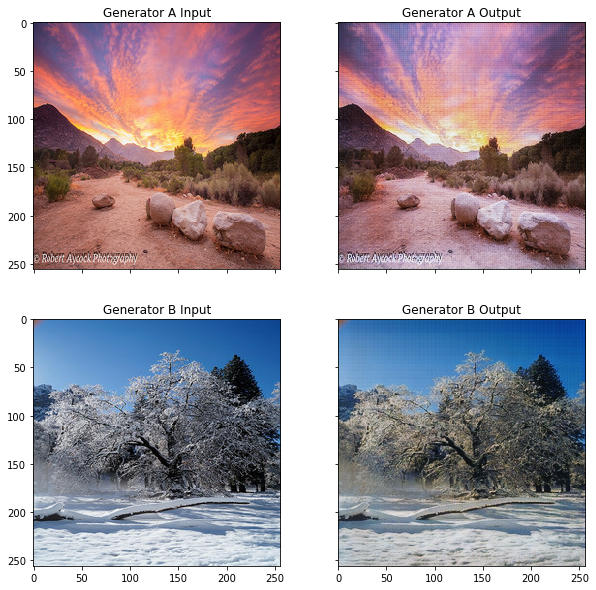

Time taken for epoch 18 batch index 0 is 0.30553197860717773 seconds

discriminator A:  1.4049089
discriminator B:  1.4493647
generator: 2.1271822452545166



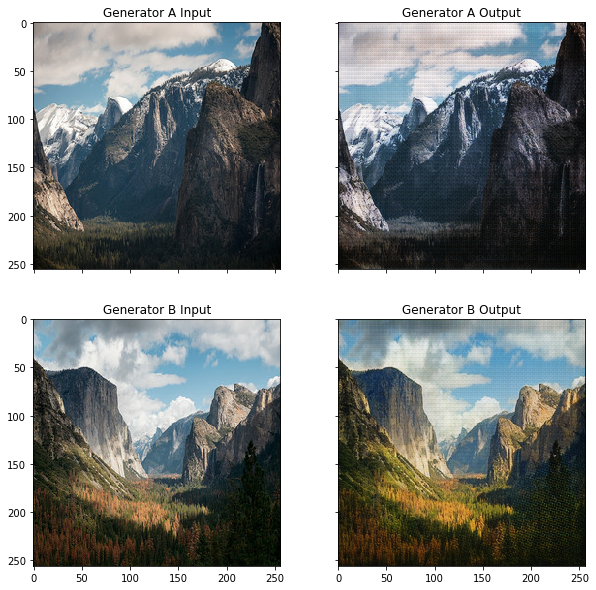

Time taken for epoch 19 batch index 0 is 0.3096616268157959 seconds

discriminator A:  1.3769978
discriminator B:  1.4007847
generator: 2.1096718311309814



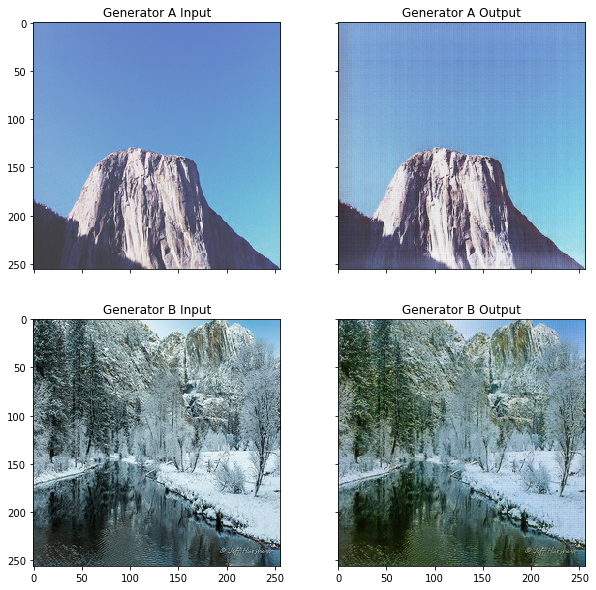

Time taken for epoch 20 batch index 0 is 0.30389881134033203 seconds

discriminator A:  1.4092841
discriminator B:  1.3908894
generator: 2.326869010925293



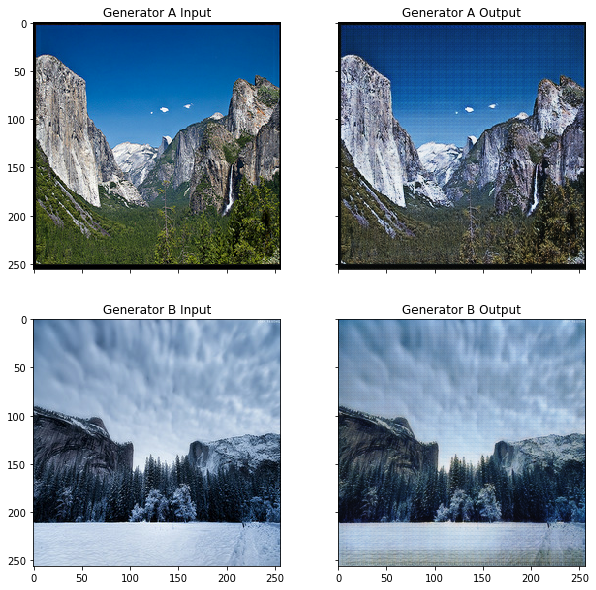

Time taken for epoch 21 batch index 0 is 0.3010270595550537 seconds

discriminator A:  1.3635612
discriminator B:  1.3776306
generator: 2.4168455600738525



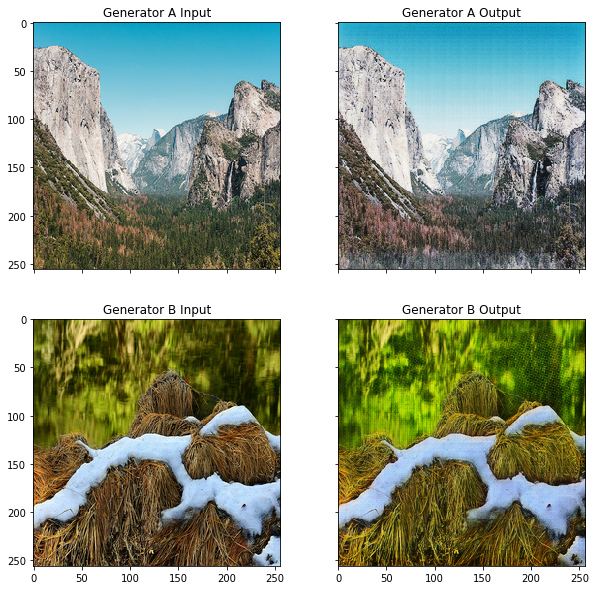

Time taken for epoch 22 batch index 0 is 0.3026258945465088 seconds

discriminator A:  1.3855821
discriminator B:  1.4072677
generator: 2.0771422386169434



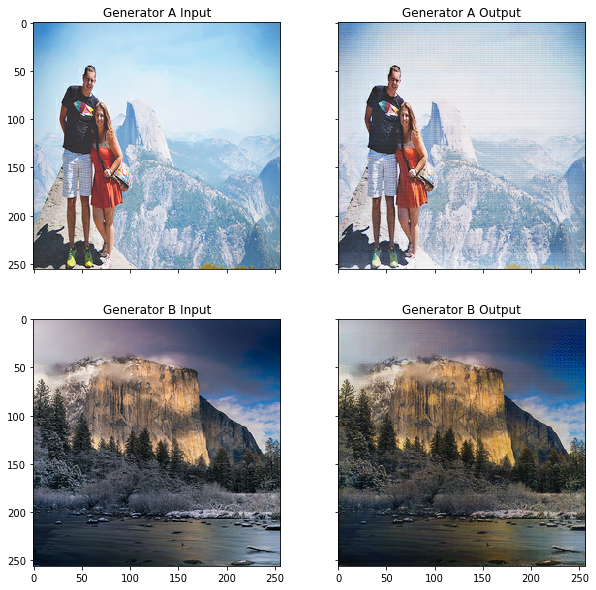

Time taken for epoch 23 batch index 0 is 0.3023064136505127 seconds

discriminator A:  1.423101
discriminator B:  1.4077965
generator: 2.233370542526245



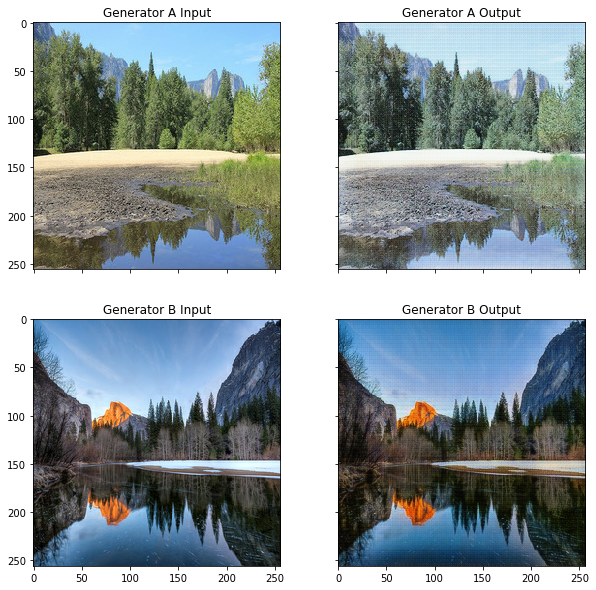

Time taken for epoch 24 batch index 0 is 0.30597925186157227 seconds

discriminator A:  1.3920579
discriminator B:  1.3891436
generator: 2.508793592453003



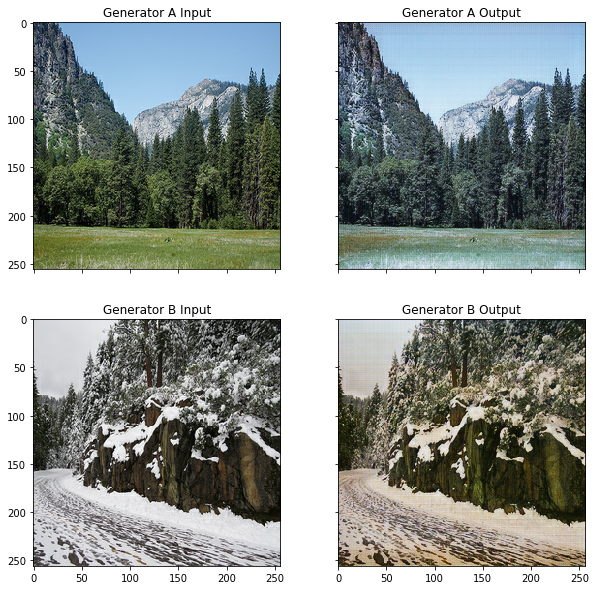

Time taken for epoch 25 batch index 0 is 0.30507874488830566 seconds

discriminator A:  1.3870442
discriminator B:  1.393997
generator: 2.407095432281494



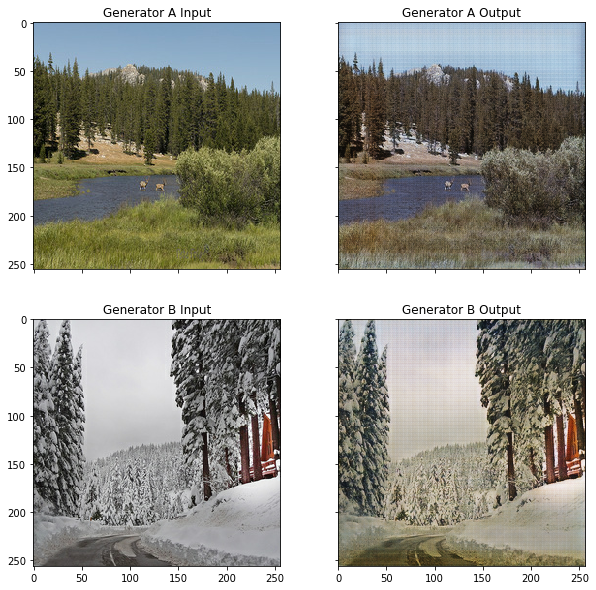

Time taken for epoch 26 batch index 0 is 0.302295446395874 seconds

discriminator A:  1.3713946
discriminator B:  1.3935697
generator: 2.2383251190185547



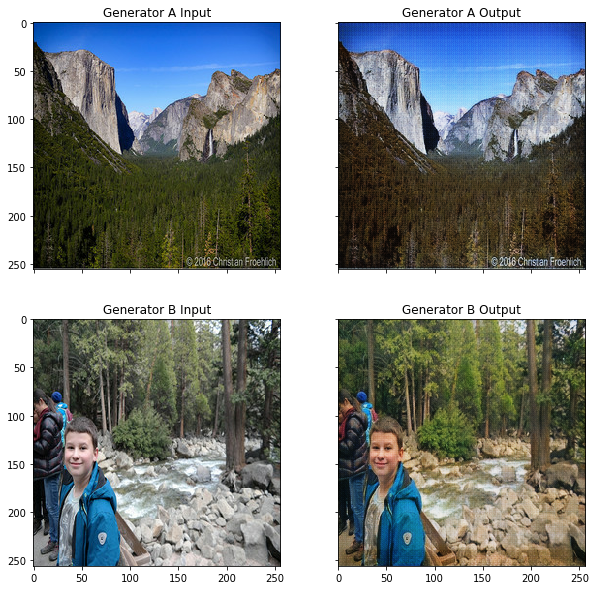

Time taken for epoch 27 batch index 0 is 0.3046844005584717 seconds

discriminator A:  1.3884577
discriminator B:  1.3646767
generator: 2.495617389678955



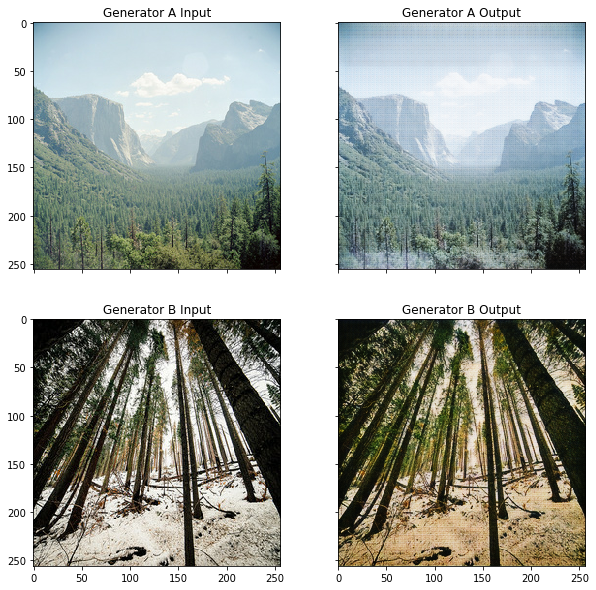

Time taken for epoch 28 batch index 0 is 0.307861328125 seconds

discriminator A:  1.4056582
discriminator B:  1.630237
generator: 1.87312912940979



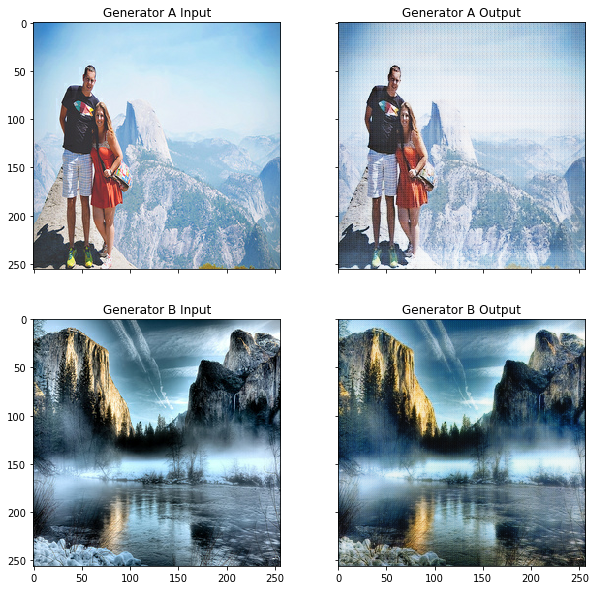

Time taken for epoch 29 batch index 0 is 0.3025779724121094 seconds

discriminator A:  1.3788751
discriminator B:  1.3860887
generator: 2.256514549255371



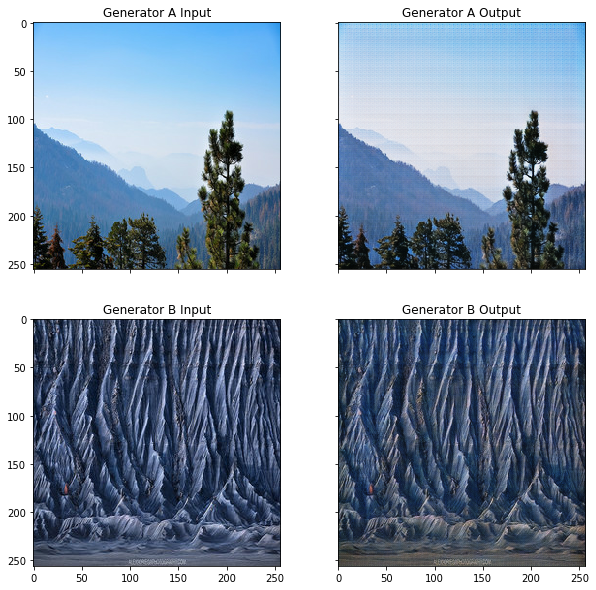

Time taken for epoch 30 batch index 0 is 0.3013296127319336 seconds

discriminator A:  1.3909065
discriminator B:  1.3927091
generator: 2.373612642288208



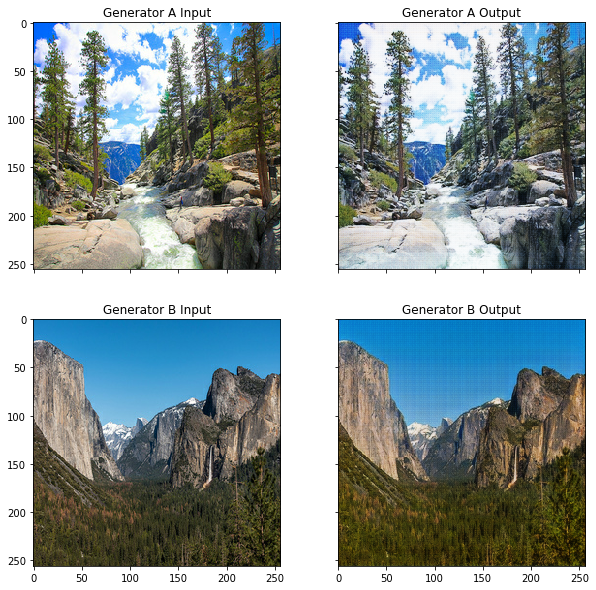

Time taken for epoch 31 batch index 0 is 0.31034183502197266 seconds

discriminator A:  1.3835526
discriminator B:  1.3913298
generator: 2.1570777893066406



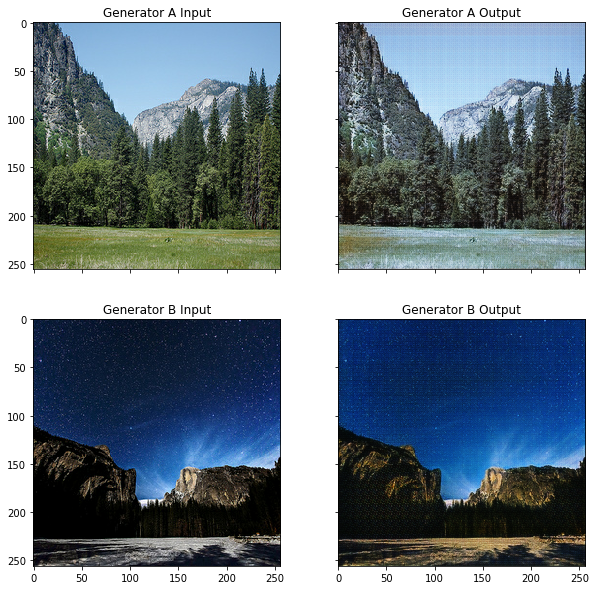

Time taken for epoch 32 batch index 0 is 0.30595970153808594 seconds

discriminator A:  1.3942608
discriminator B:  1.3801806
generator: 2.3686225414276123



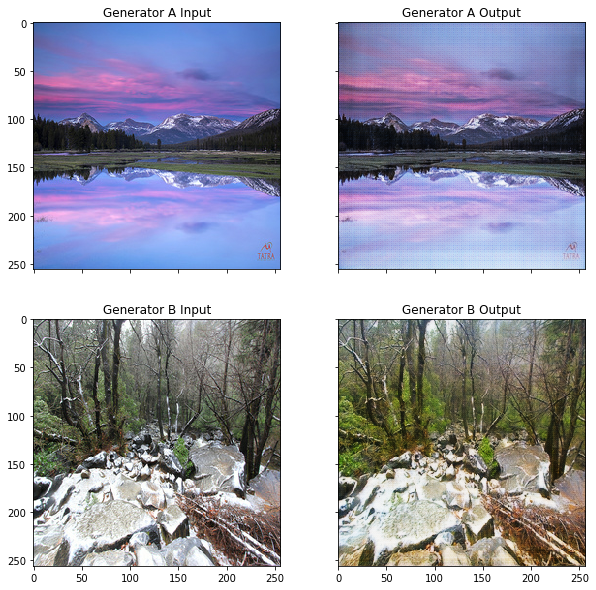

Time taken for epoch 33 batch index 0 is 0.3096792697906494 seconds

discriminator A:  1.3882394
discriminator B:  1.3738663
generator: 2.3443617820739746



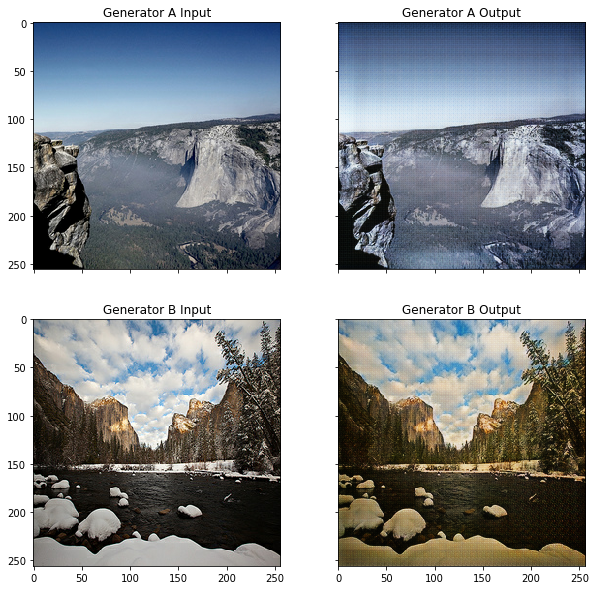

Time taken for epoch 34 batch index 0 is 0.30890774726867676 seconds

discriminator A:  1.4081413
discriminator B:  1.1091862
generator: 2.243400812149048



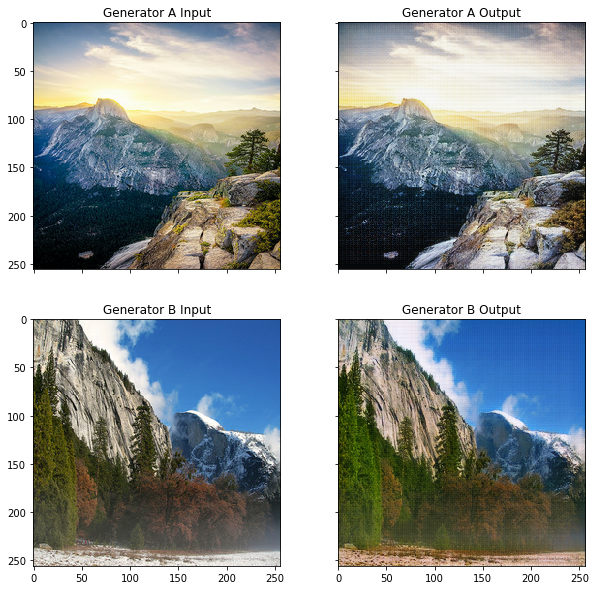

Time taken for epoch 35 batch index 0 is 0.2810063362121582 seconds

discriminator A:  1.4061561
discriminator B:  1.4060153
generator: 2.148062229156494



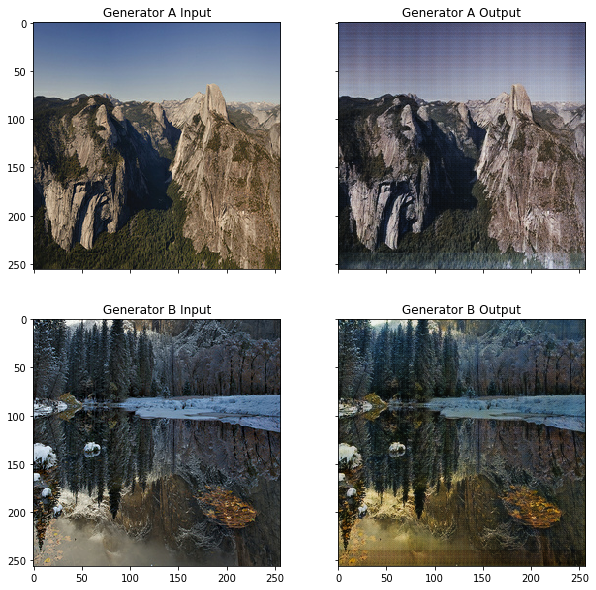

Time taken for epoch 36 batch index 0 is 0.2816798686981201 seconds

discriminator A:  1.3947091
discriminator B:  1.3839622
generator: 2.0950231552124023



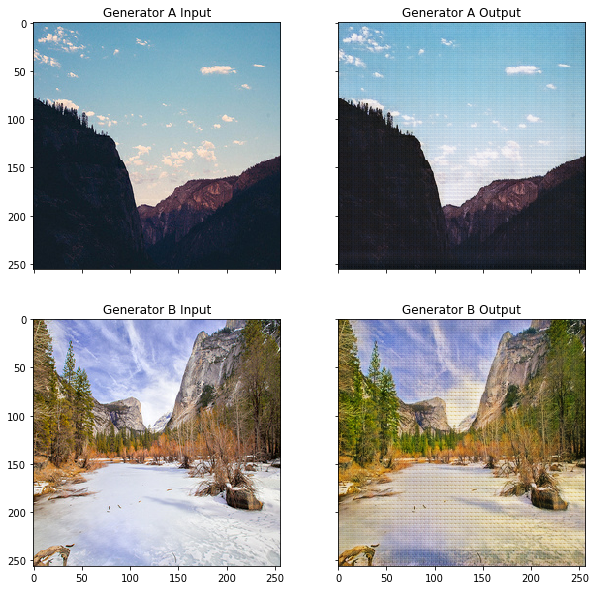

Time taken for epoch 37 batch index 0 is 0.28693437576293945 seconds

discriminator A:  1.3571262
discriminator B:  1.3684306
generator: 2.163638114929199



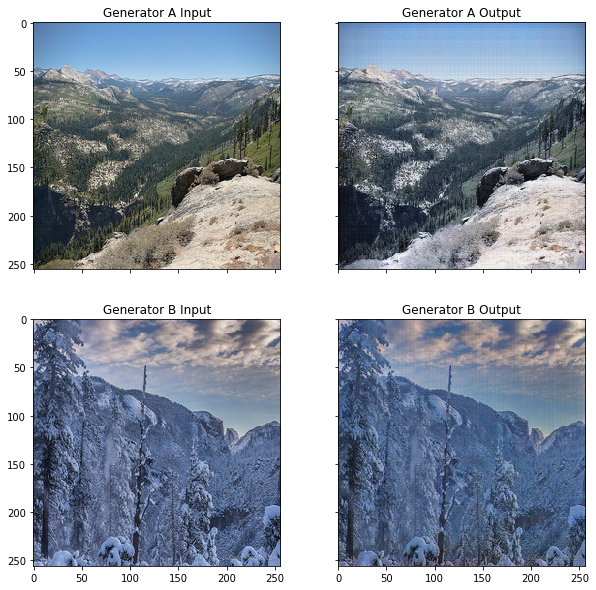

Time taken for epoch 38 batch index 0 is 0.28627943992614746 seconds

discriminator A:  1.3659183
discriminator B:  1.3915405
generator: 2.3813719749450684



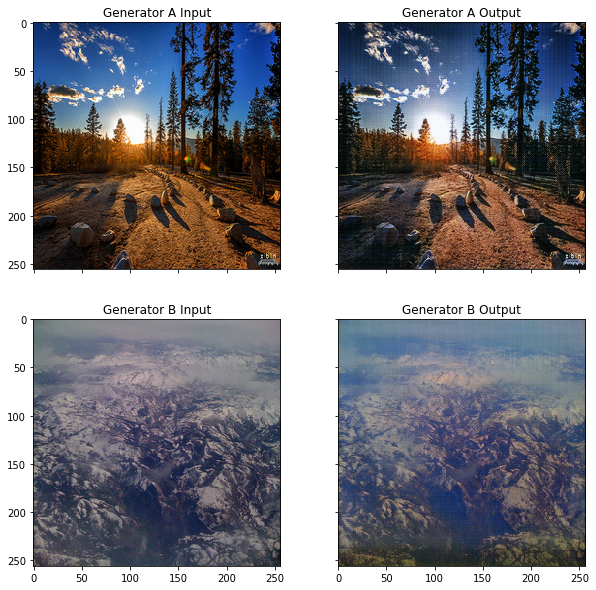

Time taken for epoch 39 batch index 0 is 0.2899003028869629 seconds

discriminator A:  1.3475227
discriminator B:  1.3527447
generator: 2.073066473007202



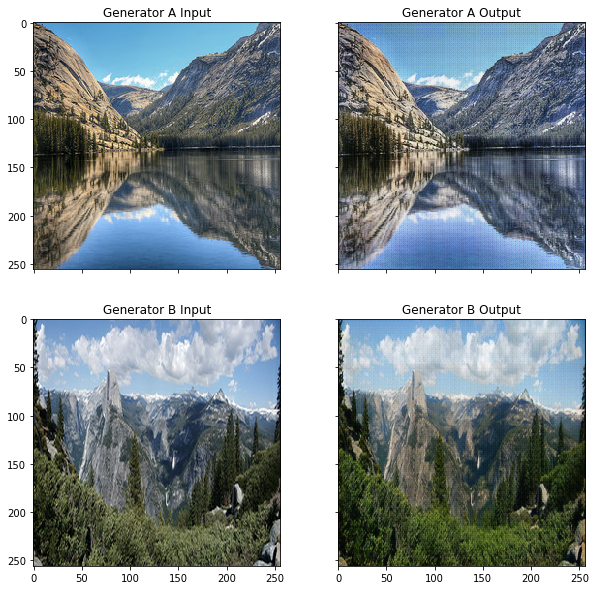

Time taken for epoch 40 batch index 0 is 0.2932267189025879 seconds

discriminator A:  1.38221
discriminator B:  1.6538599
generator: 1.6058893203735352



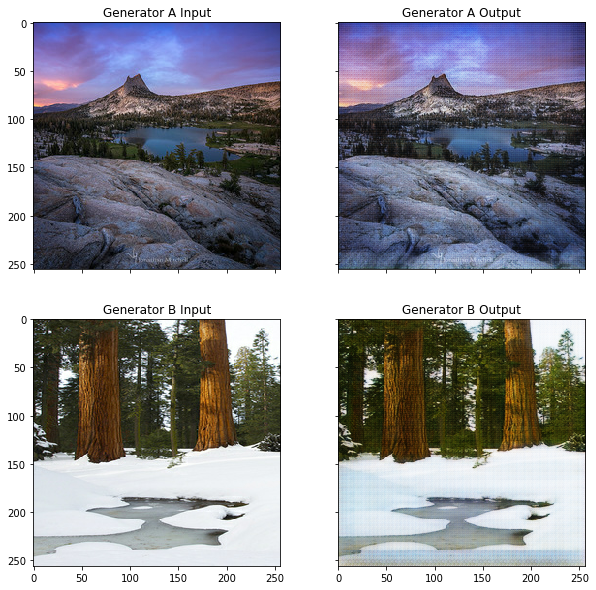

Time taken for epoch 41 batch index 0 is 0.2927532196044922 seconds

discriminator A:  1.4011209
discriminator B:  1.4035892
generator: 2.033381462097168



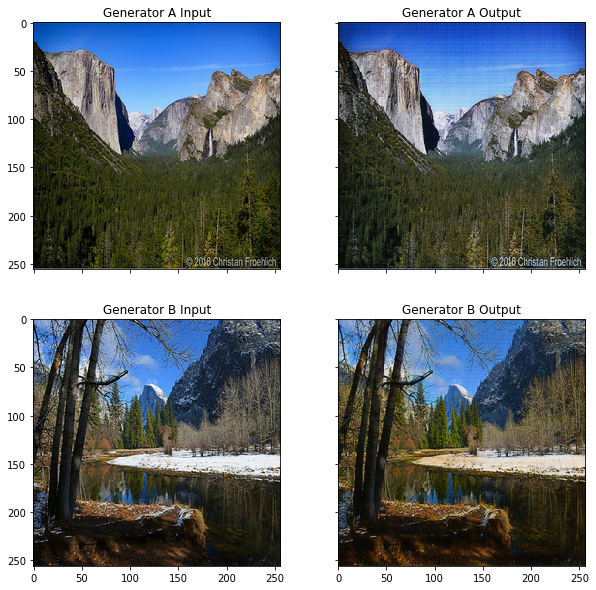

Time taken for epoch 42 batch index 0 is 0.294266939163208 seconds

discriminator A:  1.3926914
discriminator B:  1.3983943
generator: 2.0915963649749756



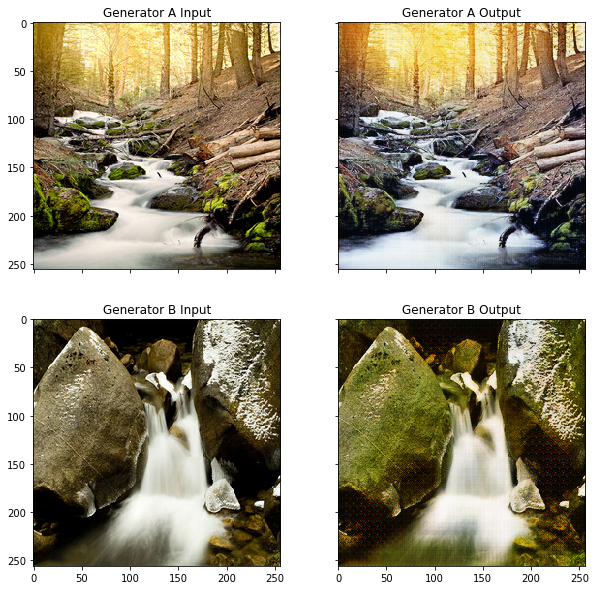

Time taken for epoch 43 batch index 0 is 0.29448747634887695 seconds

discriminator A:  1.4014444
discriminator B:  1.3985521
generator: 2.131223440170288



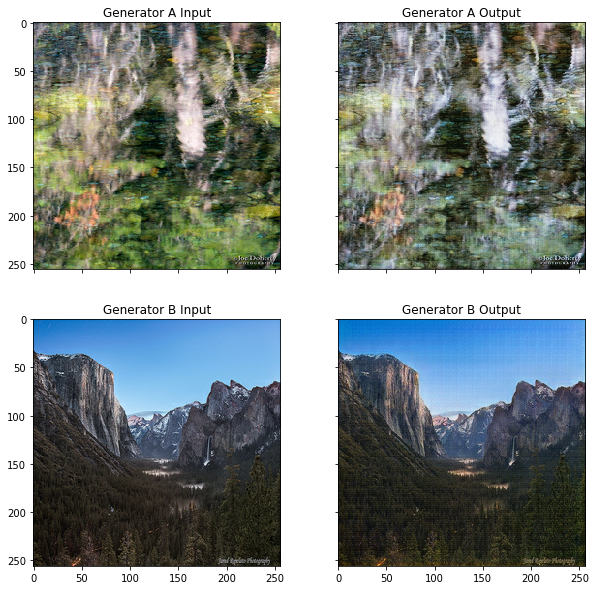

Time taken for epoch 44 batch index 0 is 0.3016371726989746 seconds

discriminator A:  1.3670855
discriminator B:  1.4145014
generator: 1.994666576385498



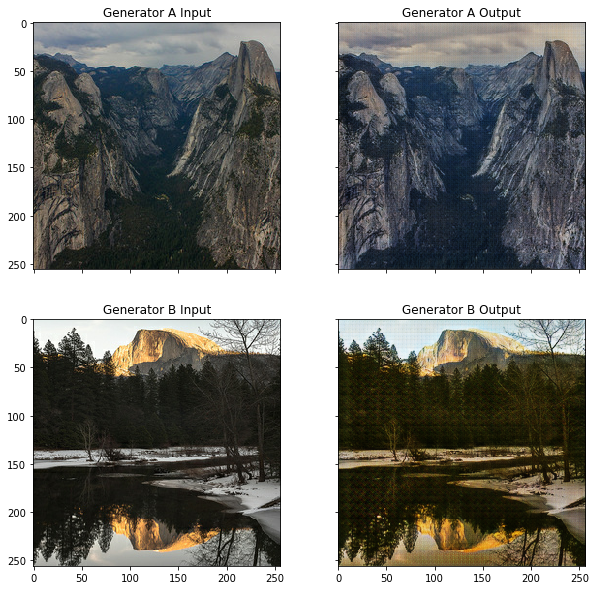

Time taken for epoch 45 batch index 0 is 0.2986314296722412 seconds

discriminator A:  1.4428127
discriminator B:  1.4091718
generator: 2.085765838623047



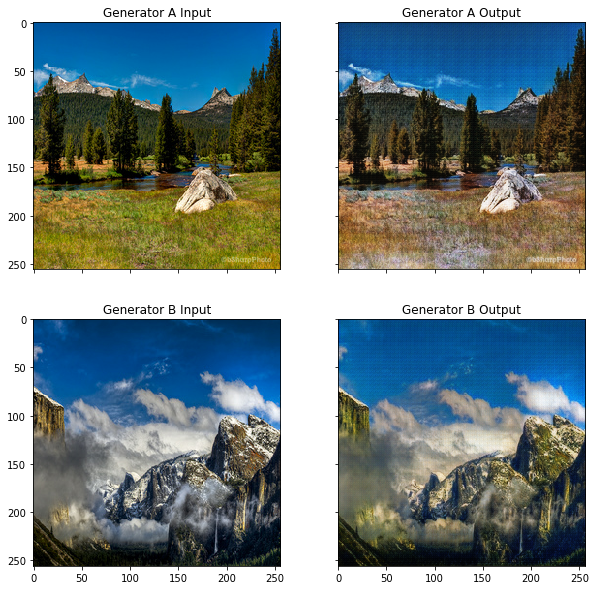

Time taken for epoch 46 batch index 0 is 0.29680490493774414 seconds

discriminator A:  1.3653362
discriminator B:  1.3908435
generator: 2.1273393630981445



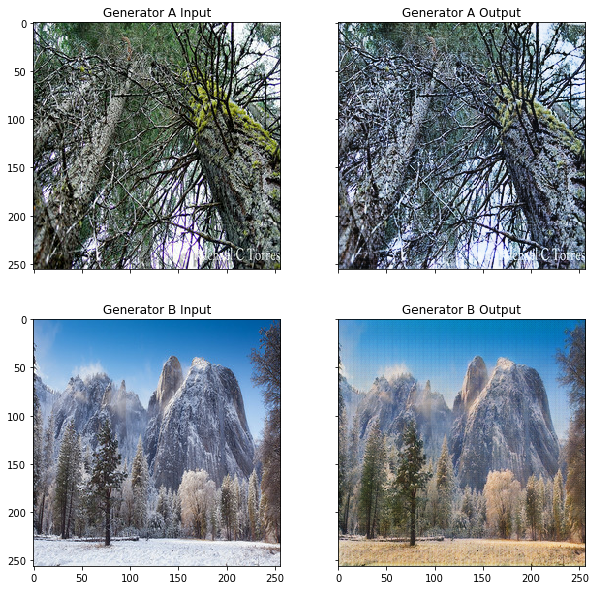

Time taken for epoch 47 batch index 0 is 0.29600000381469727 seconds

discriminator A:  1.3252668
discriminator B:  1.4436463
generator: 1.9175723791122437



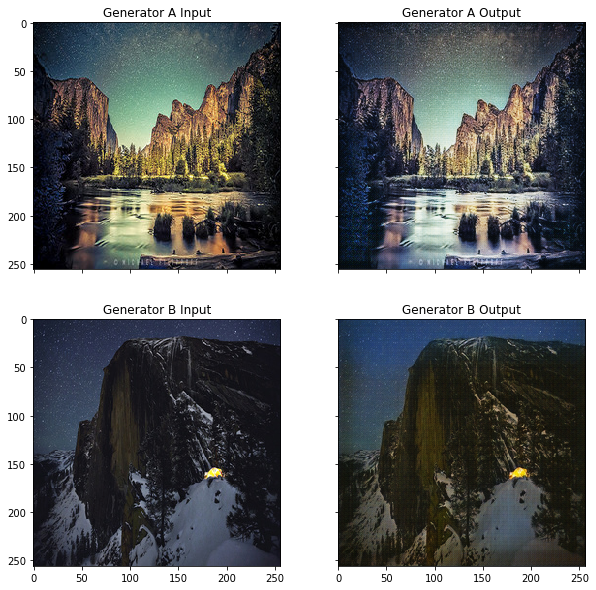

Time taken for epoch 48 batch index 0 is 0.2955048084259033 seconds

discriminator A:  1.3746767
discriminator B:  1.3982277
generator: 2.146541118621826



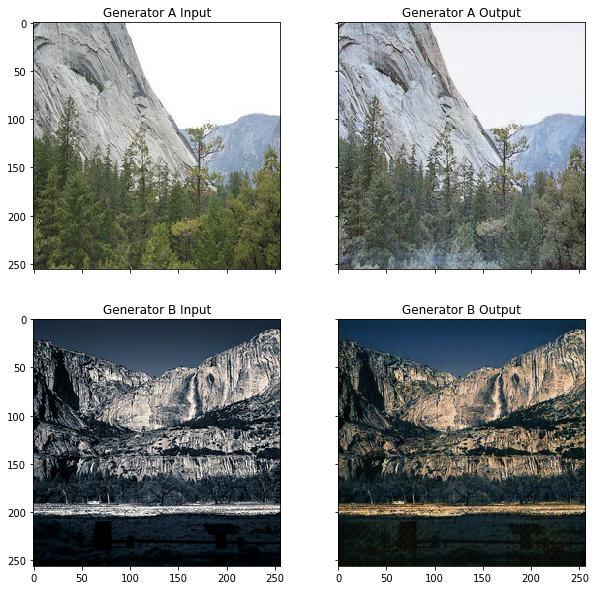

Time taken for epoch 49 batch index 0 is 0.30249857902526855 seconds

discriminator A:  1.3758252
discriminator B:  1.3887417
generator: 2.417036533355713



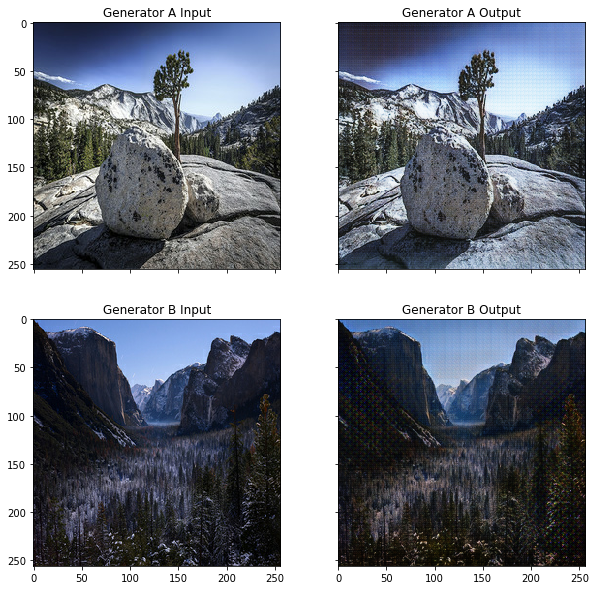

In [28]:
train(train_A, train_B, EPOCHS)

In [29]:
discriminator_A.save_weights('discriminator_A.h5')
discriminator_B.save_weights('discriminator_B.h5')
generator_AB.save_weights('generator_AB.h5')
generator_BA.save_weights('generator_BA.h5')

In [30]:
discriminator_A.load_weights('./discriminator_A.h5')
discriminator_B.load_weights('./discriminator_B.h5')
generator_AB.load_weights('./generator_AB.h5')
generator_BA.load_weights('./generator_BA.h5')

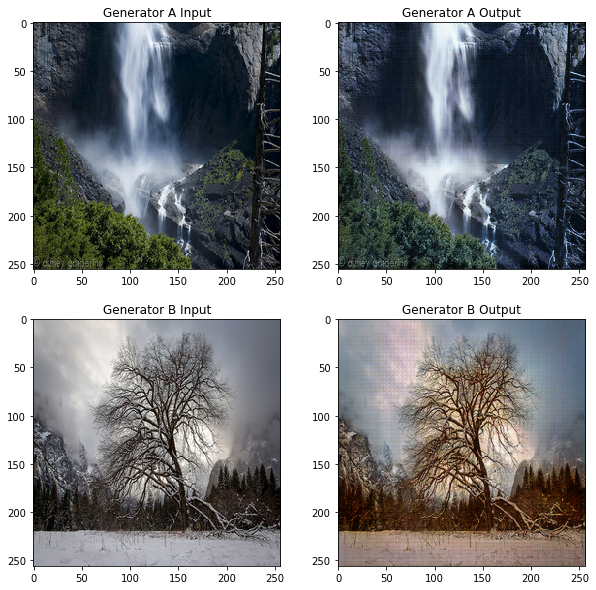

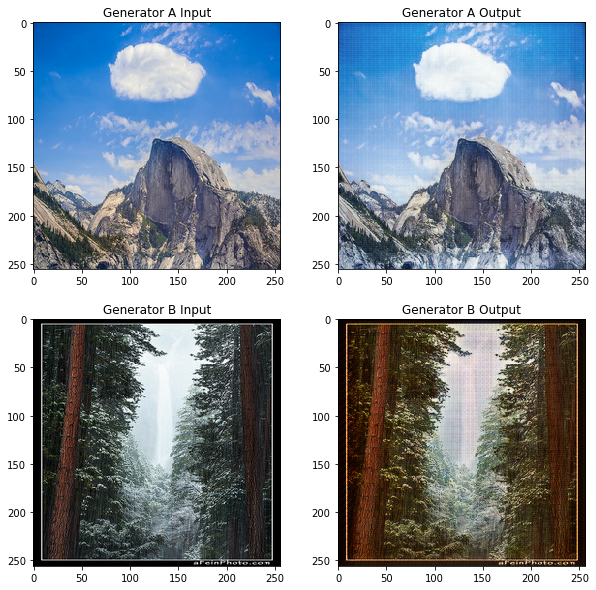

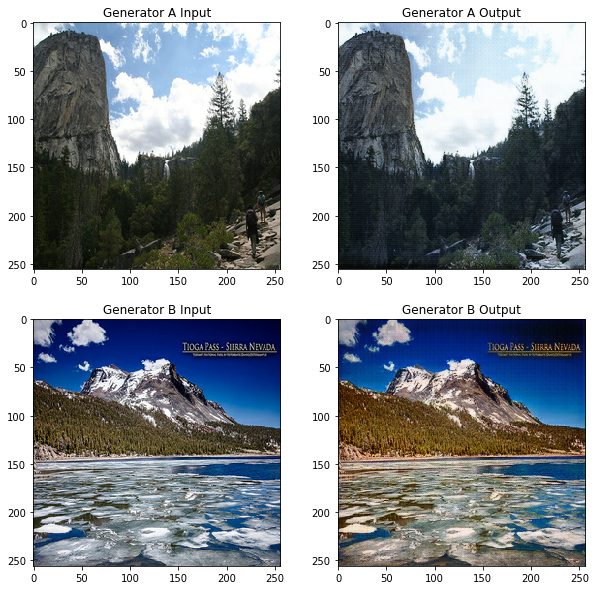

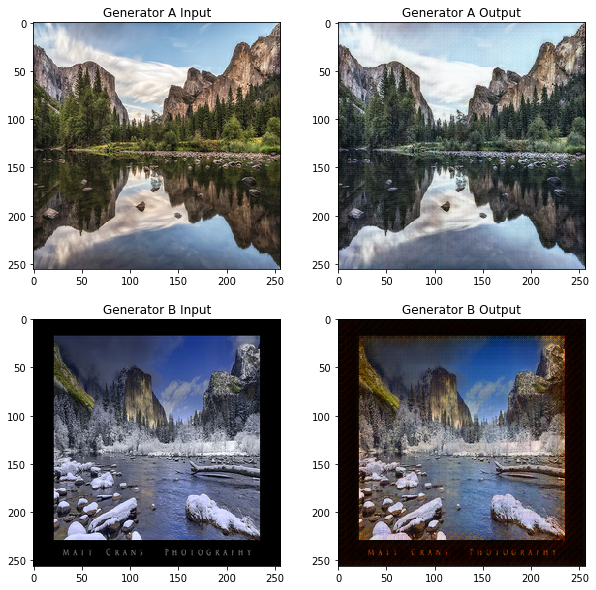

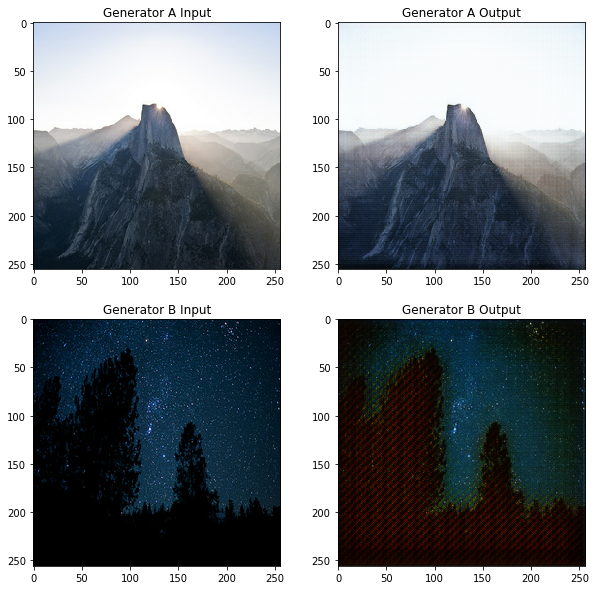

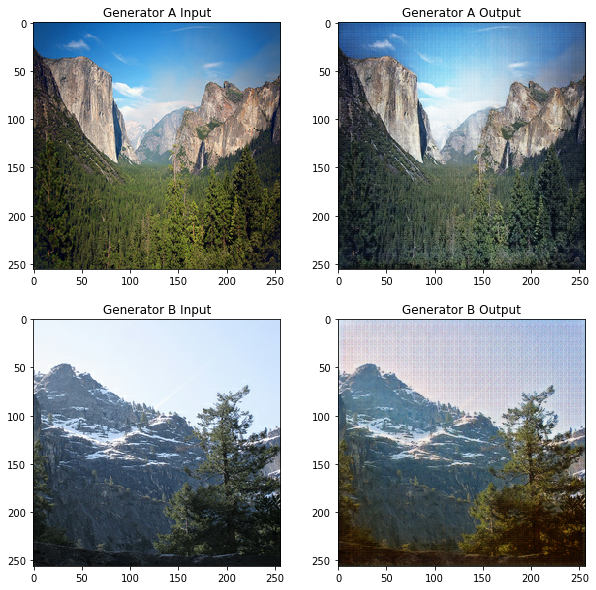

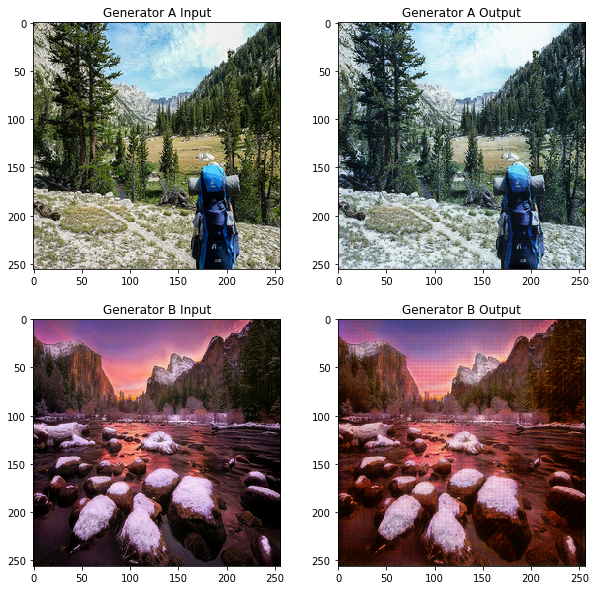

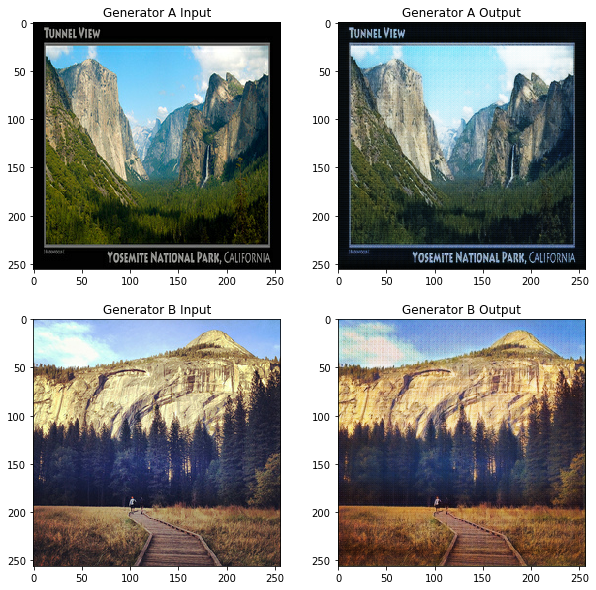

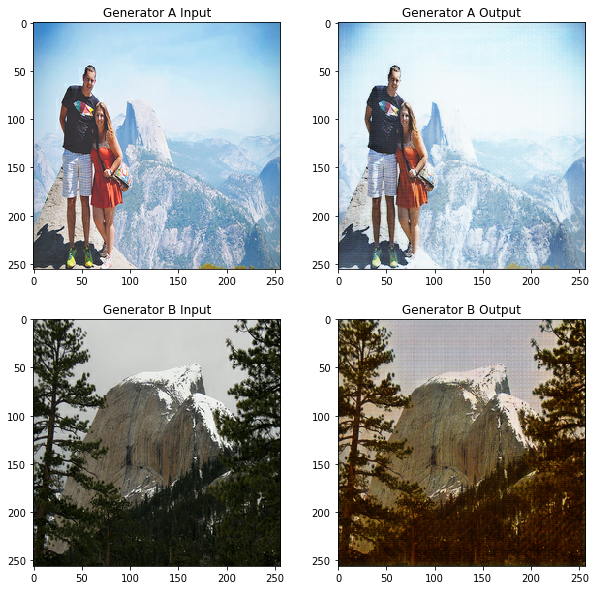

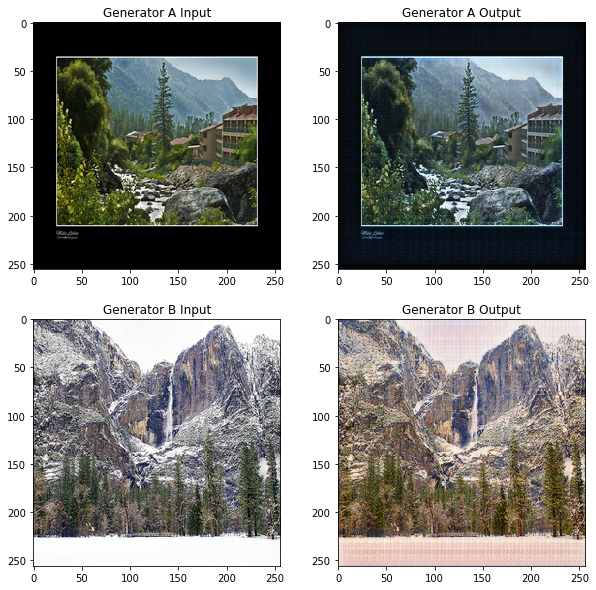

In [31]:
count = 10
for batch_i, (imgs_A, imgs_B) in enumerate(zip(test_A, test_B)):
    fake_B = generator_AB(imgs_A, training=False)
    fake_A = generator_BA(imgs_B, training=False)
    
    fig, axs = plt.subplots(2, 2, figsize=(10, 10))

    axs[0,0].imshow(imgs_A[0]*0.5 + 0.5)
    axs[0,0].set_title("Generator A Input")
    axs[0,1].imshow(fake_B[0]*0.5 + 0.5)
    axs[0,1].set_title("Generator A Output")
    axs[1,0].imshow(imgs_B[0]*0.5 + 0.5)
    axs[1,0].set_title("Generator B Input")
    axs[1,1].imshow(fake_A[0]*0.5 + 0.5)
    axs[1,1].set_title("Generator B Output")
    plt.show()
    
    count -= 1
    if count <= 0:
        break